
# Business Insights and Recommendations

## Project Objective

This notebook investigates business problems identified during the initial sales analysis. It focuses on profitability risks, discount patterns, regional performance, and product-level opportunities.

## Business Questions

1. Which subcategories contribute most to total losses?
2. How does profitability vary across discount levels?
3. Which regions require profitability improvement?
4. Which categories and subcategories should receive management attention?
5. What actions could improve profitability?

## Analytical Approach

We will use Python, Pandas, and Matplotlib to investigate these questions and translate the results into evidence-based business recommendations.


In [9]:
import os
from getpass import getpass

if not os.environ.get("PGPASSWORD"):
    os.environ["PGPASSWORD"] = getpass("PostgreSQL password: ")

In [10]:

import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

PROJECT_ROOT = Path(r"D:\sales-performance-analysis")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from python.db_config import engine

query = """
SELECT *
FROM analytics.sales_clean
"""

with engine.connect() as connection:
    df = pd.read_sql(query, connection)

print(f"Loaded {len(df):,} sales records.")


Loaded 10,194 sales records.


In [11]:
with engine.connect() as connection:
    total_rows = connection.execute(
        text("SELECT COUNT(*) FROM analytics.sales_clean")
    ).scalar()

print(f"Database connection successful: {total_rows:,} rows")

Database connection successful: 10,194 rows



## 1. Which Product Subcategories Are Losing Money?

We will calculate revenue, profit, profit margin, and loss-making sales lines by subcategory. The objective is to identify the largest sources of losses and prioritize further investigation.


In [12]:

subcategory_insights = (
    df.groupby(["category", "sub_category"], as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        sales_lines=("profit", "size"),
        loss_making_lines=("profit", lambda x: (x < 0).sum()),
    )
)

subcategory_insights["profit_margin_pct"] = (
    subcategory_insights["profit"]
    / subcategory_insights["revenue"]
    * 100
)

loss_making_subcategories = (
    subcategory_insights[
        subcategory_insights["profit"] < 0
    ]
    .sort_values("profit")
)

display(loss_making_subcategories)


,category,sub_category,revenue,profit,sales_lines,loss_making_lines,profit_margin_pct
3,Furniture,Tables,208020.28,-17753.33,326,205,-8.534423
0,Furniture,Bookcases,115361.24,-3632.08,232,111,-3.148440
12,Office Supplies,Supplies,46725.48,-1171.40,192,33,-2.506983


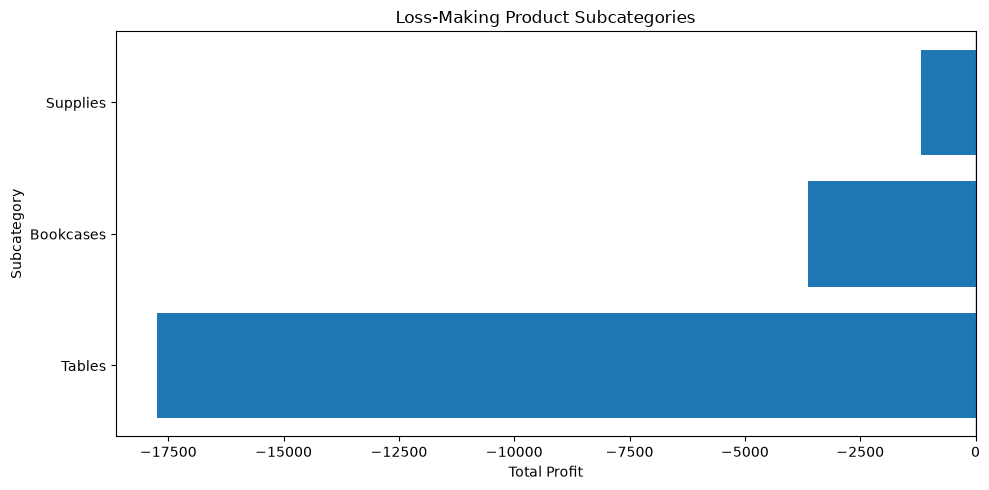

In [13]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    loss_making_subcategories["sub_category"],
    loss_making_subcategories["profit"],
)

ax.axvline(0, linewidth=1)
ax.set_title("Loss-Making Product Subcategories")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Subcategory")

plt.tight_layout()
plt.show()



## 2. Are Discounts Associated with Losses in Weak Subcategories?

This analysis focuses on Tables, Bookcases, and Supplies. We compare their profitability across discount levels to identify patterns that may help prioritize pricing and discount reviews.


In [14]:

focus_categories = ["Tables", "Bookcases", "Supplies"]

focus_df = df[df["sub_category"].isin(focus_categories)].copy()

discount_subcategory = (
    focus_df.groupby(
        ["sub_category", "discount"],
        as_index=False,
        observed=True,
    )
    .agg(
        sales_lines=("profit", "size"),
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        loss_making_lines=("profit", lambda x: (x < 0).sum()),
    )
)

discount_subcategory["profit_margin_pct"] = (
    discount_subcategory["profit"]
    / discount_subcategory["revenue"]
    * 100
)

display(
    discount_subcategory.sort_values(
        ["sub_category", "discount"]
    ).style.format({
        "discount": "{:.0%}",
        "sales_lines": "{:,.0f}",
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "loss_making_lines": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)


,sub_category,discount,sales_lines,revenue,profit,loss_making_lines,profit_margin_pct
0,Bookcases,0%,60,"31,935.98","6,075.75",0,19.02%
1,Bookcases,15%,52,"27,558.59","1,418.97",17,5.15%
2,Bookcases,20%,48,"27,178.12",168.59,23,0.62%
3,Bookcases,30%,10,"4,282.69",-555.87,9,-12.98%
4,Bookcases,32%,27,"14,493.45","-2,391.16",27,-16.50%
5,Bookcases,50%,18,"7,308.46","-4,255.83",18,-58.23%
6,Bookcases,70%,17,"2,603.95","-4,092.53",17,-157.17%
7,Supplies,0%,119,"31,611.17","1,736.08",0,5.49%
8,Supplies,20%,73,"15,114.31","-2,907.48",33,-19.24%
9,Tables,0%,76,"71,706.23","13,334.88",0,18.60%


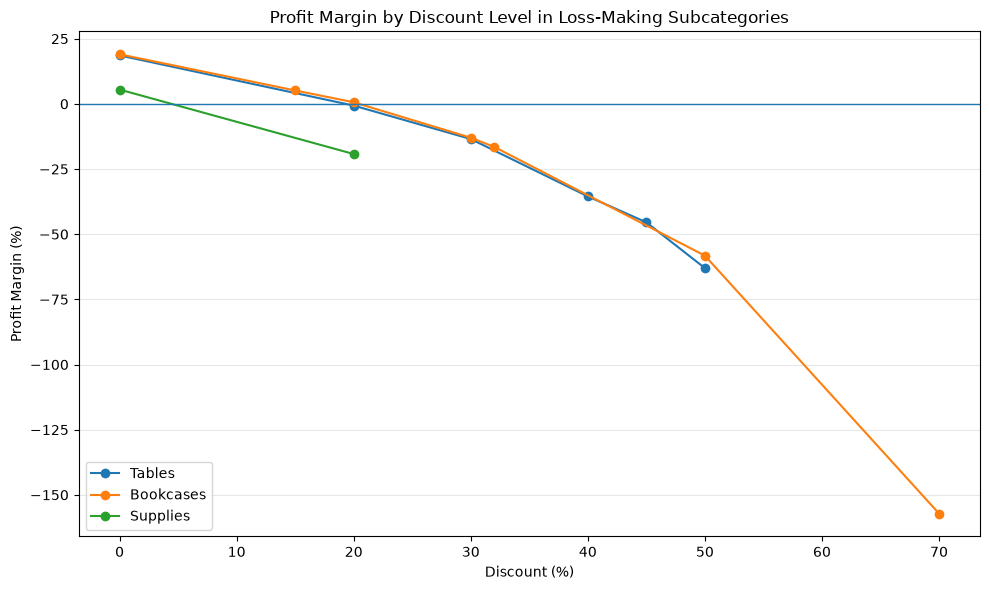

In [15]:

fig, ax = plt.subplots(figsize=(10, 6))

for subcategory in focus_categories:
    subset = discount_subcategory[
        discount_subcategory["sub_category"] == subcategory
    ].sort_values("discount")

    ax.plot(
        subset["discount"] * 100,
        subset["profit_margin_pct"],
        marker="o",
        label=subcategory,
    )

ax.axhline(0, linewidth=1)
ax.set_title("Profit Margin by Discount Level in Loss-Making Subcategories")
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Profit Margin (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



## 3. Where Is Profitability Weak Despite Revenue?

This analysis compares revenue and profit margin across regions and categories. It helps identify areas that may need closer investigation rather than relying on sales volume alone.


In [16]:

region_insights = (
    df.groupby("region", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique"),
    )
)

region_insights["profit_margin_pct"] = (
    region_insights["profit"] / region_insights["revenue"] * 100
)

display(
    region_insights.sort_values(
        "profit_margin_pct",
        ascending=True,
    ).style.format({
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "orders": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)


,region,revenue,profit,orders,profit_margin_pct
0,Central,"503,170.62","39,865.07","1,179",7.92%
2,South,"391,721.90","46,749.38",822,11.93%
1,East,"691,828.22","94,882.94","1,475",13.71%
3,West,"739,813.70","110,798.54","1,635",14.98%


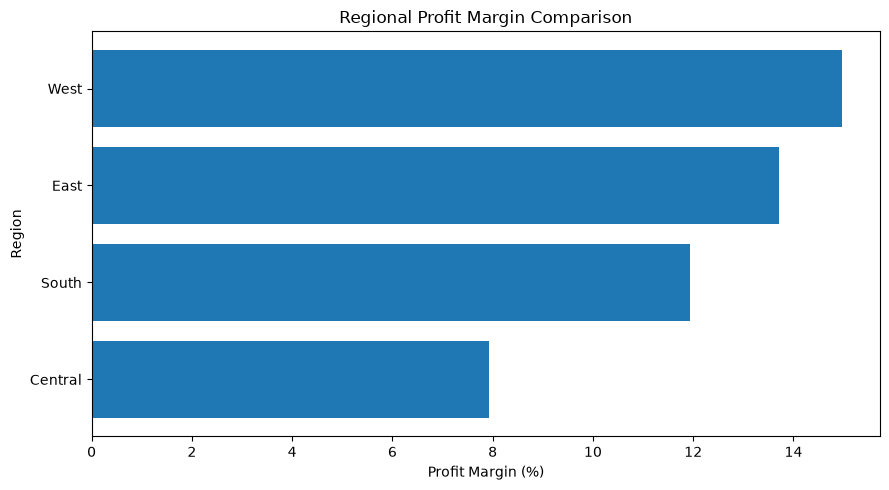

In [17]:

fig, ax = plt.subplots(figsize=(9, 5))

region_plot = region_insights.sort_values("profit_margin_pct")

ax.barh(
    region_plot["region"],
    region_plot["profit_margin_pct"],
)

ax.set_title("Regional Profit Margin Comparison")
ax.set_xlabel("Profit Margin (%)")
ax.set_ylabel("Region")

plt.tight_layout()
plt.show()



## 4. Which Customer Segments Contribute Most?

We compare Consumer, Corporate, and Home Office segments by revenue, profit, order volume, and profit margin.


In [18]:

segment_insights = (
    df.groupby("segment", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
    )
)

segment_insights["profit_margin_pct"] = (
    segment_insights["profit"] / segment_insights["revenue"] * 100
)

display(
    segment_insights.sort_values(
        "revenue",
        ascending=False,
    ).style.format({
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "orders": "{:,.0f}",
        "customers": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)



,segment,revenue,profit,orders,customers,profit_margin_pct
0,Consumer,"1,170,659.72","136,370.69","2,628",416,11.65%
1,Corporate,"715,806.18","94,249.40","1,552",239,13.17%
2,Home Office,"440,068.54","61,675.84",931,149,14.02%


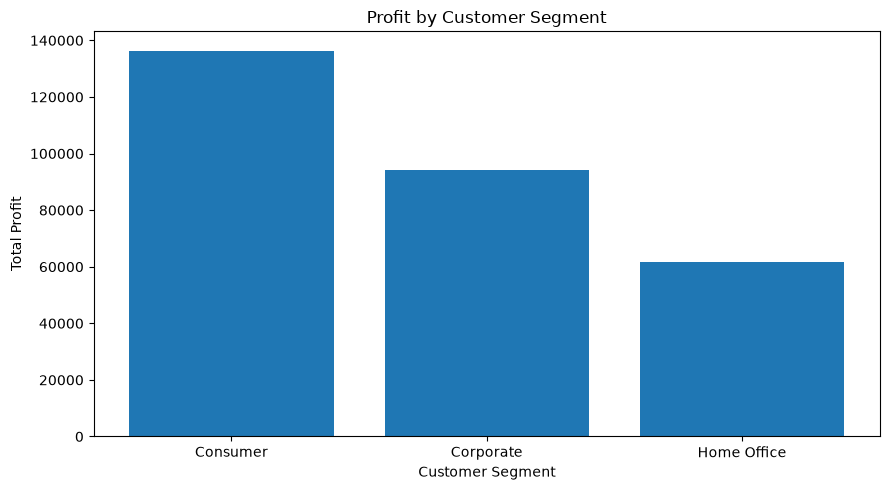

In [19]:

fig, ax = plt.subplots(figsize=(9, 5))

segment_plot = segment_insights.sort_values("profit", ascending=False)

ax.bar(
    segment_plot["segment"],
    segment_plot["profit"],
)

ax.set_title("Profit by Customer Segment")
ax.set_ylabel("Total Profit")
ax.set_xlabel("Customer Segment")

plt.tight_layout()
plt.show()



## 5. Business Recommendations and Action Plan

Based on the profitability, discount, regional, and subcategory analyses, the following actions are recommended.

### Priority 1 — Investigate High-Discount Transactions
**Finding:** Sales lines with discounts above 30% have an aggregate profit margin of -48.22%, and approximately 97.8% of these lines are loss-making.

**Recommended action:**
- Review high-discount transactions and their associated costs.
- Introduce margin-based discount approval thresholds.
- Monitor profit and profit margin alongside revenue when evaluating promotions.

**Success metric:** Reduce the share of loss-making high-discount transactions while maintaining appropriate sales volume.

### Priority 2 — Review Loss-Making Product Subcategories
**Finding:** Tables, Bookcases, and Supplies have negative total profit.

**Recommended action:**
- Examine product-level pricing, costs, and discount patterns.
- Identify products that repeatedly generate losses.
- Evaluate whether price changes, supplier negotiations, or discount restrictions are appropriate.

**Success metric:** Improve profit and profit margin for the identified subcategories.

### Priority 3 — Investigate Regional Profitability
**Finding:** Central has the lowest regional profit margin at 7.92%.

**Recommended action:**
- Compare the region's product mix and discount patterns with stronger regions.
- Investigate loss-making products and transaction-level profitability.
- Develop targeted improvement measures based on the results.

**Success metric:** Improve Central's profit margin without unnecessarily sacrificing profitable sales.

### Priority 4 — Monitor Profitability at Multiple Levels
**Finding:** Positive aggregate profit can conceal loss-making individual transactions, as seen in Binders.

**Recommended action:**
- Track revenue, profit, profit margin, and loss-making sales lines.
- Monitor performance by category, subcategory, region, and discount group.
- Review results regularly and evaluate whether interventions improve profitability.

**Success metric:** Better visibility into profitability risks and measurable improvements over time.

### Data Limitations

The dataset contains 989 orders dated after October 26, 2026. The origin and validity of these records remain unconfirmed. Findings should therefore be interpreted with this limitation in mind.

The observed relationship between discounts and losses does not prove causation. Recommendations should be tested against validated transaction and cost data before implementation.

## Conclusion

The analysis identifies several areas for further investigation: high-discount transactions, loss-making product subcategories, and weaker regional profitability. A profitability-focused monitoring approach can help management prioritize decisions using evidence rather than revenue alone.


In [20]:

action_plan = pd.DataFrame({
    "Priority": [
        1,
        2,
        3,
        4,
    ],
    "Business Issue": [
        "High-discount losses",
        "Loss-making subcategories",
        "Low Central region margin",
        "Hidden transaction-level losses",
    ],
    "Recommended Action": [
        "Review discount approvals and transaction margins",
        "Investigate pricing, costs, and product discounts",
        "Analyze regional product mix and discount patterns",
        "Monitor profit and loss-making lines",
    ],
    "Success Metric": [
        "Share of loss-making high-discount sales",
        "Subcategory profit and margin",
        "Regional profit margin",
        "Loss-making transaction rate",
    ],
})

display(action_plan)


,Priority,Business Issue,Recommended Action,Success Metric
0,1,High-discount losses,Review discount approvals and transaction margins,Share of loss-making high-discount sales
1,2,Loss-making subcategories,"Investigate pricing, costs, and product discounts",Subcategory profit and margin
2,3,Low Central region margin,Analyze regional product mix and discount patt...,Regional profit margin
3,4,Hidden transaction-level losses,Monitor profit and loss-making lines,Loss-making transaction rate
